# Лабораторная работа № 10. Байесовские модели

**Тема:** «Разработка программного продукта бота для определения сорта стекла»

**Исходные данные:** Kaggle — [uciml/glass](https://www.kaggle.com/uciml/glass) (Glass Identification Data Set: 214 образцов стекла, 9 признаков — показатель преломления RI и содержание оксидов Na, Mg, Al, Si, K, Ca, Ba, Fe; целевая переменная `Type` — сорт стекла).

## Цель работы
Применить наивный байесовский классификатор (GaussianNB, BernoulliNB) для определения сорта стекла и проанализировать вероятностные предсказания.

## 1. Теоретическая часть

**1. Байесовский подход к классификации.** Для объекта x выбирается класс с наибольшей апостериорной вероятностью P(c | x): сначала оценивают, насколько класс вероятен вообще и насколько вероятны наблюдаемые признаки в этом классе, а затем комбинируют по теореме Байеса.

**2. Теорема Байеса:** P(c | x) = P(x | c) · P(c) / P(x), где P(c) — априорная вероятность класса, P(x | c) — правдоподобие (вероятность признаков при условии класса), P(x) — вероятность признаков (нормировочная константа), P(c | x) — апостериорная вероятность.

**3. Допущение условной независимости.** В наивном байесовском классификаторе признаки считаются независимыми при заданном классе: P(x | c) = ∏ P(xᵢ | c). Это сильно упрощает расчёт (оцениваются одномерные распределения), но на практике нарушается при коррелированных признаках.

**4. Априорная и апостериорная вероятности.** Априорная — вероятность класса до наблюдения признаков (доля класса в обучающей выборке). Апостериорная — вероятность класса после учёта значений признаков объекта.

**5. Преимущества и ограничения.** Плюсы: быстрое обучение, работа на малых выборках, естественные вероятности, устойчивость к шуму. Минусы: нереалистичное допущение независимости, неточные (чрезмерно уверенные) вероятности, предположение о виде распределения (для GaussianNB — нормальное). В сравнении с линейными моделями они не учитывают взаимосвязи признаков, но не требуют итерационной оптимизации.

## 2. Практическая часть

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

URL  = "https://archive.ics.uci.edu/ml/machine-learning-databases/glass/glass.data"
COLS = ["Id", "RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe", "Type"]
FEATURES = ["RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe"]
TYPE_NAMES = {1: "окна зданий (float)", 2: "окна зданий (non-float)",
              3: "окна авто (float)", 5: "контейнеры",
              6: "посуда", 7: "фары"}

def load_glass():
    """Набор Kaggle uciml/glass (glass.csv). Если файл не загружен в Colab,
    берём тот же набор из репозитория UCI."""
    if os.path.exists("glass.csv"):
        return pd.read_csv("glass.csv")
    return pd.read_csv(URL, names=COLS).drop(columns="Id")

df = load_glass()

# ---------- сквозной пайплайн подготовки данных (ЛР 5-7) ----------
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif, RFE, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

def clean_glass(d):
    """ЛР 5: пропуски, допустимые пределы, дубликаты."""
    d = d.copy()
    d = d.dropna()
    ok = d[["Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe"]].apply(lambda s: s.between(0, 100)).all(axis=1)
    ok &= d["RI"].between(1.3, 1.7)
    return d[ok].drop_duplicates().reset_index(drop=True)

def scale_glass(d):
    """ЛР 6: стандартизация признаков (целевая Type не масштабируется)."""
    s = d.copy()
    s[FEATURES] = StandardScaler().fit_transform(d[FEATURES])
    return s

def select_glass(s):
    """ЛР 7: три метода отбора (фильтр, обёртка, встроенный) + голосование >= 2."""
    X, y = s[FEATURES], s["Type"]
    f1 = set(X.columns[SelectKBest(f_classif, k=6).fit(X, y).get_support()])
    f2 = set(X.columns[RFE(LogisticRegression(max_iter=2000), n_features_to_select=6).fit(X, y).get_support()])
    f3 = set(X.columns[SelectFromModel(RandomForestClassifier(n_estimators=300, random_state=42), threshold="median").fit(X, y).get_support()])
    votes = {f: (f in f1) + (f in f2) + (f in f3) for f in FEATURES}
    keep = [f for f in FEATURES if votes[f] >= 2]
    return s[keep + ["Type"]], keep

clean  = clean_glass(df)
scaled = scale_glass(clean)
selected, SEL = select_glass(scaled)

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             r2_score, mean_absolute_error, mean_squared_error)
X, y = selected[SEL], selected["Type"]
CLASSES = np.array(sorted(y.unique()))
def split(rs=42):
    return train_test_split(X, y, test_size=0.2, stratify=y, random_state=rs)
X_train, X_test, y_train, y_test = split(42)
print("Входная выборка (после отбора признаков):", selected.shape, "| признаки:", SEL)
print("train:", X_train.shape, "| test:", X_test.shape)
print("Классы в train:", y_train.value_counts().sort_index().to_dict(), "| в test:", y_test.value_counts().sort_index().to_dict())
def report(model, name, Xte=None, yte=None):
    Xte = X_test if Xte is None else Xte; yte = y_test if yte is None else yte
    p = model.predict(Xte)
    return {"модель": name, "accuracy": accuracy_score(yte, p), "F1 macro": f1_score(yte, p, average="macro"),
            "F1 weighted": f1_score(yte, p, average="weighted")}

Входная выборка (после отбора признаков): (213, 7) | признаки: ['Na', 'Mg', 'Al', 'K', 'Ca', 'Ba']
train: (170, 6) | test: (43, 6)
Классы в train: {1: 55, 2: 61, 3: 14, 5: 10, 6: 7, 7: 23} | в test: {1: 14, 2: 15, 3: 3, 5: 3, 6: 2, 7: 6}


### 2.1. Базовый уровень

GaussianNB: accuracy = 0.535, F1 macro = 0.472
                         precision    recall  f1-score   support

    окна зданий (float)       0.52      0.86      0.65        14
окна зданий (non-float)       0.50      0.20      0.29        15
      окна авто (float)       0.00      0.00      0.00         3
             контейнеры       0.50      0.33      0.40         3
                 посуда       0.50      1.00      0.67         2
                   фары       0.83      0.83      0.83         6

               accuracy                           0.53        43
              macro avg       0.48      0.54      0.47        43
           weighted avg       0.52      0.53      0.49        43

Суммы вероятностей по строкам (должны быть 1): [1. 1. 1. 1. 1.]


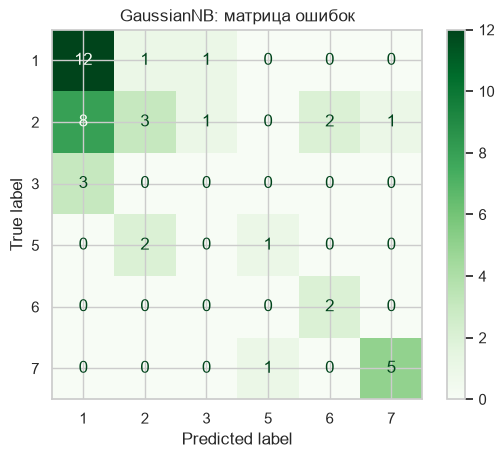

In [2]:
from sklearn.naive_bayes import GaussianNB, BernoulliNB
gnb = GaussianNB().fit(X_train, y_train)
pred = gnb.predict(X_test); proba = gnb.predict_proba(X_test)
print(f"GaussianNB: accuracy = {accuracy_score(y_test, pred):.3f}, F1 macro = {f1_score(y_test, pred, average='macro'):.3f}")
print(classification_report(y_test, pred, target_names=[TYPE_NAMES[k] for k in CLASSES], zero_division=0))
print("Суммы вероятностей по строкам (должны быть 1):", proba.sum(axis=1)[:5].round(3))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=CLASSES, cmap="Greens"); plt.title("GaussianNB: матрица ошибок"); plt.show()

### 2.2. Анализ вероятностей

In [3]:
print("Априорные вероятности классов (из обучающей выборки):")
display(pd.Series(gnb.class_prior_, index=gnb.classes_).round(3).to_frame("P(c)").T)
P = pd.DataFrame(proba, columns=[f"P({k})" for k in gnb.classes_], index=y_test.index).round(3)
P["истина"] = y_test.values; P["предсказано"] = pred; P["max P"] = proba.max(axis=1).round(3)
print("Вероятности для нескольких объектов:"); display(P.head(10))

Априорные вероятности классов (из обучающей выборки):


,1,2,3,5,6,7
P(c),0.324,0.359,0.082,0.059,0.041,0.135


Вероятности для нескольких объектов:


,P(1),P(2),P(3),P(5),P(6),P(7),истина,предсказано,max P
207,0.000,0.000,0.000,0.012,0.0,0.988,7,7,0.988
168,0.000,0.792,0.000,0.206,0.0,0.002,5,2,0.792
121,0.912,0.009,0.080,0.000,0.0,0.000,2,1,0.912
171,0.000,0.000,0.000,1.000,0.0,0.000,5,5,1.000
29,0.905,0.003,0.092,0.000,0.0,0.000,1,1,0.905
2,0.926,0.017,0.057,0.000,0.0,0.000,1,1,0.926
116,0.746,0.078,0.175,0.000,0.0,0.000,2,1,0.746
128,0.000,0.970,0.000,0.019,0.0,0.011,2,2,0.970
43,0.915,0.003,0.081,0.000,0.0,0.000,1,1,0.915
52,0.748,0.251,0.001,0.000,0.0,0.000,1,1,0.748


Средняя уверенность: верные = 0.906, ошибочные = 0.851


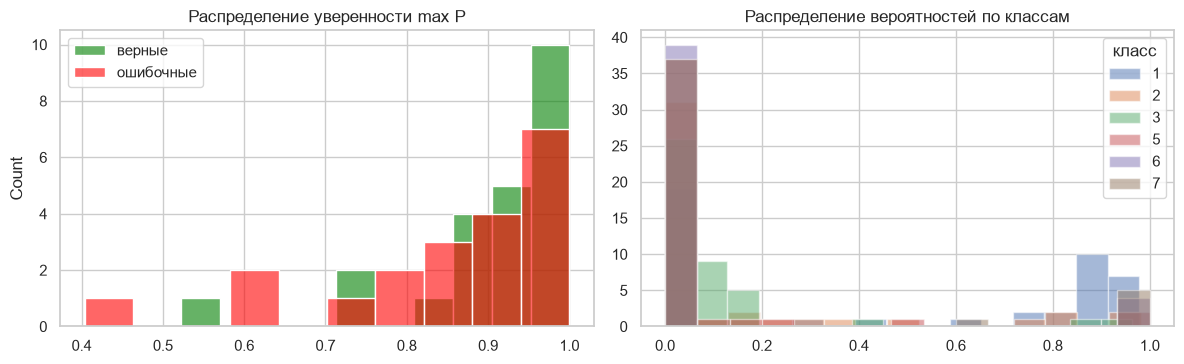

«Пограничные» объекты (max P < 0.7): 4 из 43


,P(1),P(2),P(3),P(5),P(6),P(7),истина,предсказано,max P
130,0.000,0.522,0.000,0.478,0.0,0.000,2,2,0.522
151,0.608,0.000,0.392,0.000,0.0,0.000,3,1,0.608
83,0.002,0.289,0.000,0.082,0.0,0.627,2,7,0.627
69,0.404,0.376,0.164,0.001,0.0,0.056,2,1,0.404


In [4]:
conf = proba.max(axis=1); ok = pred == y_test.values
print(f"Средняя уверенность: верные = {conf[ok].mean():.3f}, ошибочные = {conf[~ok].mean():.3f}")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(conf[ok], bins=10, color="green", label="верные", ax=ax[0], alpha=.6); sns.histplot(conf[~ok], bins=10, color="red", label="ошибочные", ax=ax[0], alpha=.6)
ax[0].set_title("Распределение уверенности max P"); ax[0].legend()
for k, col in zip(gnb.classes_, proba.T): ax[1].hist(col, bins=15, alpha=.5, label=str(k))
ax[1].set_title("Распределение вероятностей по классам"); ax[1].legend(title="класс"); plt.tight_layout(); plt.show()
border = P[(proba.max(axis=1) < 0.7)]
print(f"«Пограничные» объекты (max P < 0.7): {len(border)} из {len(P)}"); display(border.head(8))

In [5]:
wrong = P[P["истина"] != P["предсказано"]]
print("Неверно классифицированные объекты и их вероятности:"); display(wrong)
print("Значения признаков этих объектов:"); display(X_test.loc[wrong.index].round(2))

Неверно классифицированные объекты и их вероятности:


,P(1),P(2),P(3),P(5),P(6),P(7),истина,предсказано,max P
168,0.000,0.792,0.000,0.206,0.0,0.002,5,2,0.792
121,0.912,0.009,0.080,0.000,0.0,0.000,2,1,0.912
116,0.746,0.078,0.175,0.000,0.0,0.000,2,1,0.746
155,0.876,0.003,0.122,0.000,0.0,0.000,3,1,0.876
143,0.953,0.010,0.037,0.000,0.0,0.000,2,1,0.953
172,0.000,0.816,0.000,0.184,0.0,0.000,5,2,0.816
113,0.978,0.008,0.014,0.000,0.0,0.000,2,1,0.978
140,0.002,0.137,0.861,0.000,0.0,0.000,2,3,0.861
147,0.883,0.003,0.114,0.000,0.0,0.000,3,1,0.883
108,0.000,0.000,0.000,0.000,1.0,0.000,2,6,1.000


Значения признаков этих объектов:


,Na,Mg,Al,K,Ca,Ba
168,-0.16,-1.86,0.63,-0.04,1.66,-0.35
121,-0.21,0.60,0.06,0.09,-0.60,-0.35
116,0.39,0.69,0.73,0.22,-0.76,-0.35
155,0.01,0.49,-0.34,0.03,-0.21,-0.35
143,-0.51,0.35,-0.44,0.12,-0.10,-0.35
172,-0.03,-1.86,-0.10,-0.26,2.49,-0.35
113,-0.37,0.90,-0.52,0.16,-0.37,-0.35
140,-0.25,0.66,-0.77,0.11,-0.38,-0.17
147,-0.20,0.62,-0.14,0.09,-0.36,-0.35
108,0.39,-1.86,-1.80,-0.77,1.43,-0.35


**Ответ.** Средняя уверенность на верных предсказаниях выше, чем на ошибочных (≈ 0.91 против ≈ 0.85), но разница небольшая: большая часть ошибок сделана с высокой уверенностью (например, окна non-float принимаются за float с вероятностью 0.9–0.98). Это типичная особенность наивного Байеса — из-за допущения независимости он склонен переоценивать вероятности. «Пограничные» объекты (max P < 0.7) встречаются редко — всего несколько из 43.

### 2.3. Сравнение вариантов и влияние зависимых признаков

In [6]:
cm = X[SEL].corr()
pairs = cm.where(np.triu(np.ones(cm.shape, dtype=bool), 1)).stack().sort_values(key=abs, ascending=False)
print("Наиболее зависимые пары признаков (нарушают допущение независимости):"); display(pairs.head(4).round(3).to_frame("r"))
# влияние: модель на всех признаках vs на «независимых» подмножествах
dep = list(pairs.index[0]);
res = []
for name, cols in [("все признаки", SEL), (f"без {dep[1]}", [c_ for c_ in SEL if c_ != dep[1]]), (f"только пара {dep[0]}+{dep[1]}", dep)]:
    m = GaussianNB().fit(X_train[cols], y_train); p = m.predict(X_test[cols]); pr = m.predict_proba(X_test[cols]).max(axis=1)
    res.append([name, accuracy_score(y_test, p), f1_score(y_test, p, average="macro"), pr.mean()])
display(pd.DataFrame(res, columns=["набор признаков", "accuracy", "F1 macro", "средняя max P"]).round(3))

Наиболее зависимые пары признаков (нарушают допущение независимости):


r
Mg Ba -0.492
Al Ba  0.481
Mg Al -0.480
   Ca -0.446

,набор признаков,accuracy,F1 macro,средняя max P
0,все признаки,0.535,0.472,0.881
1,без Ba,0.488,0.436,0.807
2,только пара Mg+Ba,0.163,0.170,0.824


In [7]:
bnb = BernoulliNB(binarize=0.0).fit(X_train, y_train)          # признаки стандартизованы -> бинаризация: выше/ниже среднего
pb = bnb.predict(X_test); prb = bnb.predict_proba(X_test)
cmp = pd.DataFrame([report(gnb, "GaussianNB"), report(bnb, "BernoulliNB")]).set_index("модель")
cmp["средняя max P"] = [proba.max(axis=1).mean(), prb.max(axis=1).mean()]
display(cmp.round(3))
conf_g, conf_b = proba.max(axis=1), prb.max(axis=1)
print("Уверенно ошибаются (max P > 0.8):  GaussianNB =", int(((conf_g > 0.8) & (pred != y_test.values)).sum()), "| BernoulliNB =", int(((conf_b > 0.8) & (pb != y_test.values)).sum()))
print("Неуверенно классифицированные (max P < 0.5): GaussianNB =", int((conf_g < 0.5).sum()), "| BernoulliNB =", int((conf_b < 0.5).sum()))
t = X_test.copy(); t["истина"] = y_test.values; t["Gauss"] = pred; t["Bernoulli"] = pb; t["P_G"] = conf_g.round(2); t["P_B"] = conf_b.round(2)
print("Объекты, на которых модели ошибаются:"); display(t[(t["Gauss"] != t["истина"]) | (t["Bernoulli"] != t["истина"])])

,accuracy,F1 macro,F1 weighted,средняя max P
модель,,,,
GaussianNB,0.535,0.472,0.486,0.881
BernoulliNB,0.628,0.495,0.601,0.663


Уверенно ошибаются (max P > 0.8):  GaussianNB = 15 | BernoulliNB = 3
Неуверенно классифицированные (max P < 0.5): GaussianNB = 1 | BernoulliNB = 3
Объекты, на которых модели ошибаются:


,Na,Mg,Al,K,Ca,Ba,истина,Gauss,Bernoulli,P_G,P_B
168,-0.164573,-1.860172,0.627611,-0.044308,1.663174,-0.353808,5,2,5,0.79,0.73
121,-0.213668,0.597653,0.061679,0.093803,-0.600398,-0.353808,2,1,2,0.91,0.83
171,-0.495966,-1.860172,3.174302,8.764103,-1.422876,-0.353808,5,5,2,1.00,0.72
2,0.154546,0.604596,0.182950,-0.167073,-0.825349,-0.353808,1,1,2,0.93,0.53
116,0.387749,0.694855,0.728670,0.216568,-0.755052,-0.353808,2,1,2,0.75,0.70
128,0.706868,-0.922866,0.364857,-0.167073,1.128915,-0.353808,2,2,6,0.97,0.65
155,0.007261,0.493508,-0.342557,0.032420,-0.213763,-0.353808,3,1,1,0.88,0.56
143,-0.508239,0.347704,-0.443617,0.124494,-0.101287,-0.353808,2,1,1,0.95,0.60
20,-0.716894,0.604596,0.081891,0.063112,-0.305150,-0.353808,1,1,2,0.86,0.83
172,-0.029561,-1.860172,-0.100015,-0.259147,2.492681,-0.353808,5,2,2,0.82,0.33


### Итоговый текст

Байесовские модели относятся к генеративным: они моделируют, как данные порождаются каждым классом (P(x | c)), и затем по теореме Байеса вычисляют вероятность класса, тогда как дискриминативные модели (логистическая регрессия, kNN, деревья) напрямую учатся границе между классами. Сильные стороны наивного байеса — мгновенное обучение, хорошая работа на небольших выборках (у нас всего 213 образцов), встроенные вероятности классов и учёт априорных частот, а также устойчивость к шумовым признакам. Ограничения связаны с допущением условной независимости: в данных о стекле есть заметно коррелированные оксиды (Mg–Al, Mg–Ba, Ca–RI), из-за чего вероятности получаются чрезмерно уверенными, а часть ошибок делается с высокой уверенностью. GaussianNB дополнительно предполагает нормальность признаков внутри класса, которая для Ba, K и Fe с их скошенными распределениями выполняется плохо; BernoulliNB использует лишь бинарную информацию «выше/ниже среднего» и теряет информацию о величине признака, но в нашем эксперименте он оказался точнее (accuracy 0.63 против 0.54, F1 macro 0.50 против 0.47) и заметно менее самоуверенным: средняя max P 0.66 против 0.88, уверенных ошибок (P > 0.8) 3 против 15 — грубая бинаризация скорее сглаживает неверное допущение о нормальности скошенных признаков (Ba, K). Эксперимент с подмножествами признаков показал, что удаление Ba (входящего в самые зависимые пары Mg–Ba и Al–Ba) снижает точность с 0.535 до 0.488 и среднюю уверенность с 0.88 до 0.81, а модель только на паре Mg + Ba даёт всего 0.16: признак информативен для «фар», хотя и коррелирует с другими, поэтому нарушение независимости не лечится простым удалением признаков. Байесовские модели особенно эффективны в задачах с большим числом слабо связанных признаков (тексты, спам-фильтры), в начале проекта как быстрый базовый вариант и там, где нужны вероятности. Для задачи определения сорта стекла наивный байес даёт умеренное качество (accuracy 0.54–0.63) и объяснимость, но уступает kNN и ансамблям деревьев, которые учитывают взаимодействия оксидов.